
## Nishant Gupta |2026AJ05092 | Machine Learning | Assignment - 2
### End-to-End Classification, Evaluation & Deployment Workflow

---

### **Executive Summary & Assignment Objectives**

* **Dataset:** UCI Adult Census Income Dataset (`adult.csv`)
  - **Feature Count:** 14 features (exceeds minimum requirement of 12)
  - **Instance Count:** 32,561 records (exceeds minimum requirement of 500)
  - **Target Variable:** `income` (`<=50K` vs `>50K`)
* **Core Tasks:**
  1. Implement **5 Machine Learning Classification Models**:
     - Logistic Regression
     - Decision Tree Classifier
     - K-Nearest Neighbor (KNN) Classifier
     - Naive Bayes Classifier (GaussianNB)
     - Support Vector Machine (LinearSVC with Platt Calibration)
  2. Evaluate all 5 models across **6 Mandatory Performance Metrics**:
     - Accuracy
     - AUC Score (Area Under ROC Curve)
     - Precision
     - Recall
     - F1 Score
     - Matthews Correlation Coefficient (MCC)
  3. Generate **Model Comparison & In-Depth Observation Tables**.
  4. Perform **Exploratory Data Analysis (EDA)**, Outlier Inspection, and Feature Engineering.
  5. Build and serialize reusable **End-to-End Scikit-Learn Pipelines** (Preprocessing + Classifier) to `model/` for deployment.
  6. Export `test_data.csv` for the interactive **Streamlit Community Cloud Web Application**.


## 1. Environment Setup & Library Imports
Importing all required scientific computing, visualization, and machine learning libraries from `scikit-learn`, `pandas`, `numpy`, `matplotlib`, and `seaborn`.


In [1]:
# Core data manipulation and mathematical libraries
import os
import time
import warnings
import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Pipeline tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV

# Scikit-Learn Classification Models (All 5 Required by Assignment)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Scikit-Learn Evaluation Metrics 
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Serialization library for Streamlit deployment
import joblib

# Suppress minor non-critical warnings for clean output
warnings.filterwarnings('ignore')

# Set aesthetic visualization theme
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12

print("All required libraries successfully imported!")


All required libraries successfully imported!


### Environment Verification
All primary packages (`scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn`, `joblib`) are available and configured.
Next, we load the raw `adult.csv` dataset and inspect its structure, features, dimensions, and missing value patterns.


## 2. Dataset Ingestion & Initial Exploration
The **Adult Census Income** dataset was extracted by Barry Becker from the 1994 US Census Bureau database.
The prediction task is to determine whether an individual's annual income exceeds **$50,000/year** (`>50K`) or not (`<=50K`), based on demographic and employment attributes.


In [10]:
# Define dataset path
data_path = 'D:\\Sem_1\\Assignments\\StreamLit\\notebook\\data\\adult.csv'

# Read dataset into a pandas DataFrame
df_raw = pd.read_csv(data_path)

# Display dataset dimensions and initial preview
print(f"Dataset Shape: {df_raw.shape[0]:,} rows by {df_raw.shape[1]} columns")
print(f"Compliance Check: Features = {df_raw.shape[1]-1} (Min requirement: >= 12) -> PASSED")
print(f"Compliance Check: Instances = {df_raw.shape[0]:,} (Min requirement: >= 500) -> PASSED\n")

# Display first 5 records
df_raw.head()


Dataset Shape: 32,561 rows by 15 columns
Compliance Check: Features = 14 (Min requirement: >= 12) -> PASSED
Compliance Check: Instances = 32,561 (Min requirement: >= 500) -> PASSED



,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


### Initial Observations
1. The dataset contains **32,561 rows** and **15 columns** (14 input features + 1 target variable `income`).
2. Both numerical features (`age`, `fnlwgt`, `education.num`, `capital.gain`, `capital.loss`, `hours.per.week`) and categorical features (`workclass`, `education`, `marital.status`, `occupation`, `relationship`, `race`, `sex`, `native.country`) are present.
3. Notice that missing values in this UCI dataset are encoded as `'?'` characters rather than standard IEEE NaN values.


In [11]:
# Display column data types and non-null counts
print("Dataset Information & Schema:")
df_raw.info()


Dataset Information & Schema:
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


In [12]:
# Statistical summary of numerical features
df_raw.describe().T


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education.num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital.gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital.loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours.per.week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


### Schema Analysis & Summary Statistics
- Numerical features exhibit varying scales: `capital.gain` and `capital.loss` have high maximums with 75% of values being 0, while `age` spans from 17 to 90 and `hours.per.week` has a median of 40 hours.
- This wide variance in feature scales necessitates **Feature Standardization (`StandardScaler`)** prior to fitting distance-based (KNN) and gradient/margin-based (Logistic Regression, SVM) classifiers.


## 3. Data Cleaning & Missing Value Handling
In the Adult dataset, missing values are denoted by `'?'` strings with possible whitespace.
We identify which columns contain these placeholders and apply principled imputation to preserve all 32,561 samples without discarding critical data.


In [13]:
# Replace '?' and trimmed '?' with np.nan across the entire DataFrame
df_clean = df_raw.replace('?', np.nan).replace(r'^\s*\?\s*$', np.nan, regex=True)

# Calculate missing value counts and percentages
missing_counts = df_clean.isnull().sum()
missing_pct = (missing_counts / len(df_clean)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_pct.round(2)
})
missing_summary = missing_summary[missing_summary['Missing Count'] > 0]
print("Columns with Missing Values:")
display(missing_summary)


Columns with Missing Values:


,Missing Count,Percentage (%)
workclass,1836,5.64
occupation,1843,5.66
native.country,583,1.79


### Imputation Strategy: Mode Imputation
- Three categorical columns have missing values: `workclass` (1,836 missing / 5.64%), `occupation` (1,843 missing / 5.66%), and `native.country` (583 missing / 1.79%).
- Since these are purely categorical fields, and the missing fraction is modest (<6%), we impute missing entries with the **mode (most frequent category)** of each respective column.
- This adheres strictly to the rule: *Prefer to keep data instead of dropping it when possible*.


In [14]:
# Impute missing values with column mode
for col in ['workclass', 'occupation', 'native.country']:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_val)
    print(f"Imputed column '{col}' with mode: '{mode_val}'")

# Strip leading and trailing whitespace from string columns
str_cols = df_clean.select_dtypes(include=['object', 'string']).columns
for col in str_cols:
    df_clean[col] = df_clean[col].str.strip()

# Verify that no missing values remain
assert df_clean.isnull().sum().sum() == 0, "Missing values still remain!"
print("\nVerification Passed: 0 missing values remain in dataset.")


Imputed column 'workclass' with mode: 'Private'
Imputed column 'occupation' with mode: 'Prof-specialty'
Imputed column 'native.country' with mode: 'United-States'

Verification Passed: 0 missing values remain in dataset.


## 4. Comprehensive Exploratory Data Analysis (EDA)
EDA allows us to uncover distribution characteristics, class imbalance, correlations, and feature-target relationships that inform our choice of models and evaluation metrics.


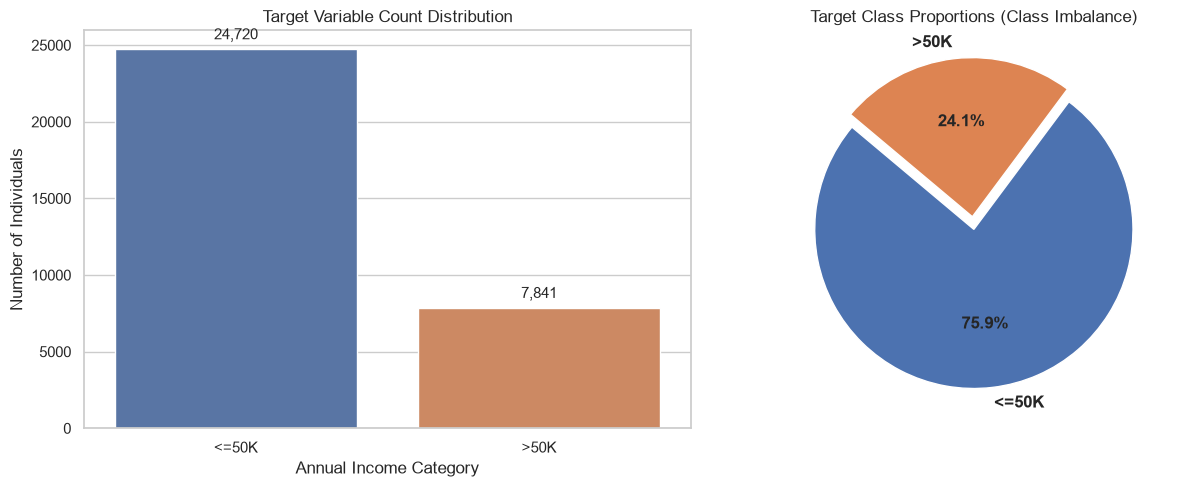

Class Distribution Breakdown:
 - <=50K: 24,720 instances (75.92%)
 - >50K: 7,841 instances (24.08%)


In [15]:
# Target variable distribution visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Bar Chart (Countplot)
sns.countplot(data=df_clean, x='income', ax=axes[0], palette=['#4C72B0', '#DD8452'], order=['<=50K', '>50K'])
axes[0].set_title('Target Variable Count Distribution')
axes[0].set_xlabel('Annual Income Category')
axes[0].set_ylabel('Number of Individuals')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, xytext=(0, 5), textcoords='offset points')

# Subplot 2: Pie Chart (Proportions)
income_counts = df_clean['income'].value_counts()
axes[1].pie(income_counts, labels=income_counts.index, autopct='%1.1f%%',
           startangle=140, colors=['#4C72B0', '#DD8452'], explode=[0, 0.08],
           textprops={'fontsize': 12, 'weight': 'bold'})
axes[1].set_title('Target Class Proportions (Class Imbalance)')

plt.tight_layout()
plt.show()

print("Class Distribution Breakdown:")
for cls, count in income_counts.items():
    print(f" - {cls}: {count:,} instances ({count / len(df_clean):.2%})")


### Critical Insight: Target Class Imbalance
- **75.92%** of individuals earn `<=50K` (Negative Class / 0).
- **24.08%** of individuals earn `>50K` (Positive Class / 1).
- **Evaluation Implication:** A trivial majority-class classifier that blindly predicts `<=50K` would achieve **~76% Accuracy** while having a useless Recall of 0% on high earners!
- Therefore, relying on Accuracy alone would be deeply flawed. **AUC Score, Precision, Recall, F1 Score, and MCC (Matthews Correlation Coefficient)** are imperative for true model benchmarking.


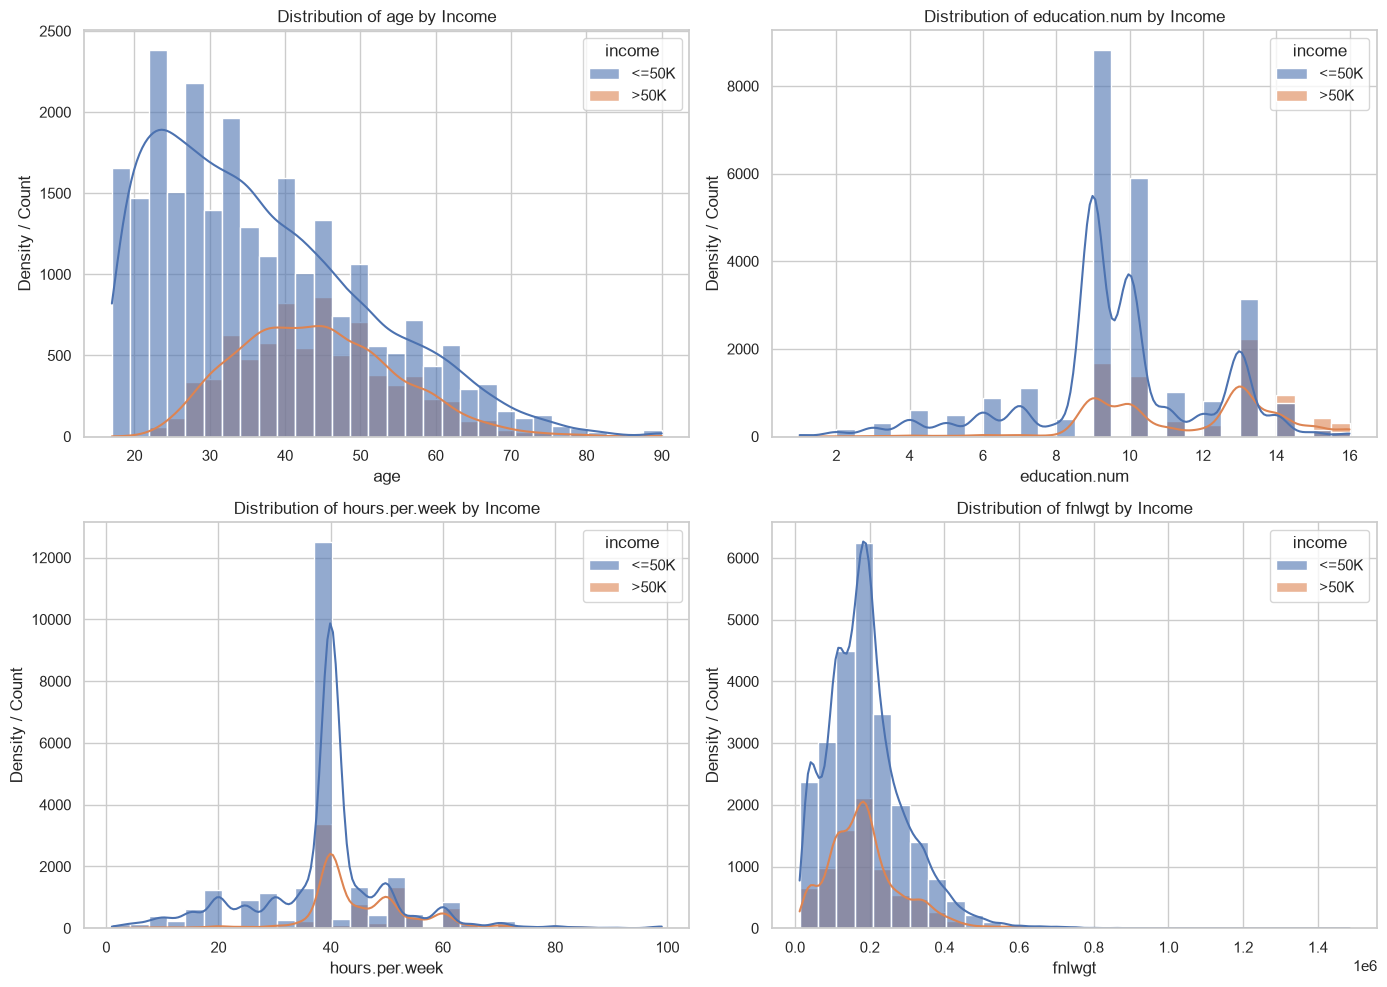

In [16]:
# Distributions of Continuous Numerical Features
num_features = ['age', 'education.num', 'hours.per.week', 'fnlwgt']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, col in enumerate(num_features):
    sns.histplot(data=df_clean, x=col, hue='income', kde=True, ax=axes[idx],
                 palette=['#4C72B0', '#DD8452'], bins=30, alpha=0.6)
    axes[idx].set_title(f'Distribution of {col} by Income')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Density / Count')

plt.tight_layout()
plt.show()


### Insights from Numerical Feature Distributions
1. **Age:** High earners (`>50K`) peak in the 40–55 age bracket, reflecting peak career earnings, whereas the `<=50K` population is heavily skewed toward younger individuals (<30 years).
2. **Education Number:** Individuals with `education.num` $\ge 13$ (corresponding to Bachelors, Masters, and Doctorates) have a markedly higher likelihood of exceeding $50K annual income.
3. **Hours per Week:** Most individuals work 40 hours/week. However, those working 45–60 hours/week comprise a significantly higher proportion of the `>50K` class.


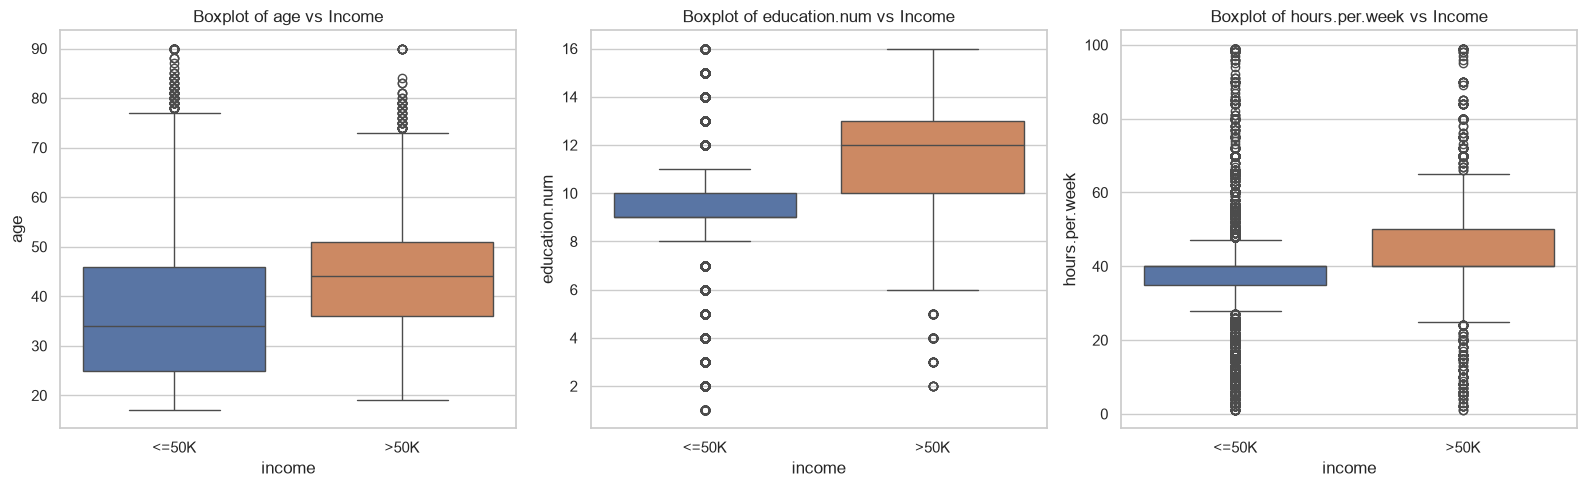

In [17]:
# Outlier analysis using boxplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

features_to_check = ['age', 'education.num', 'hours.per.week']
for i, feature in enumerate(features_to_check):
    sns.boxplot(data=df_clean, x='income', y=feature, ax=axes[i], palette=['#4C72B0', '#DD8452'])
    axes[i].set_title(f'Boxplot of {feature} vs Income')

plt.tight_layout()
plt.show()


### Insights from Boxplots
- The median age for high earners is **44 years**, compared to **34 years** for low earners.
- The median education number for high earners is **12** (Some college / Associate / Bachelors), compared to **9** (High School grad) for low earners.
- While outliers exist in `hours.per.week` (<20 or >70 hours), they represent legitimate census records and will be preserved and standardized via `StandardScaler`.


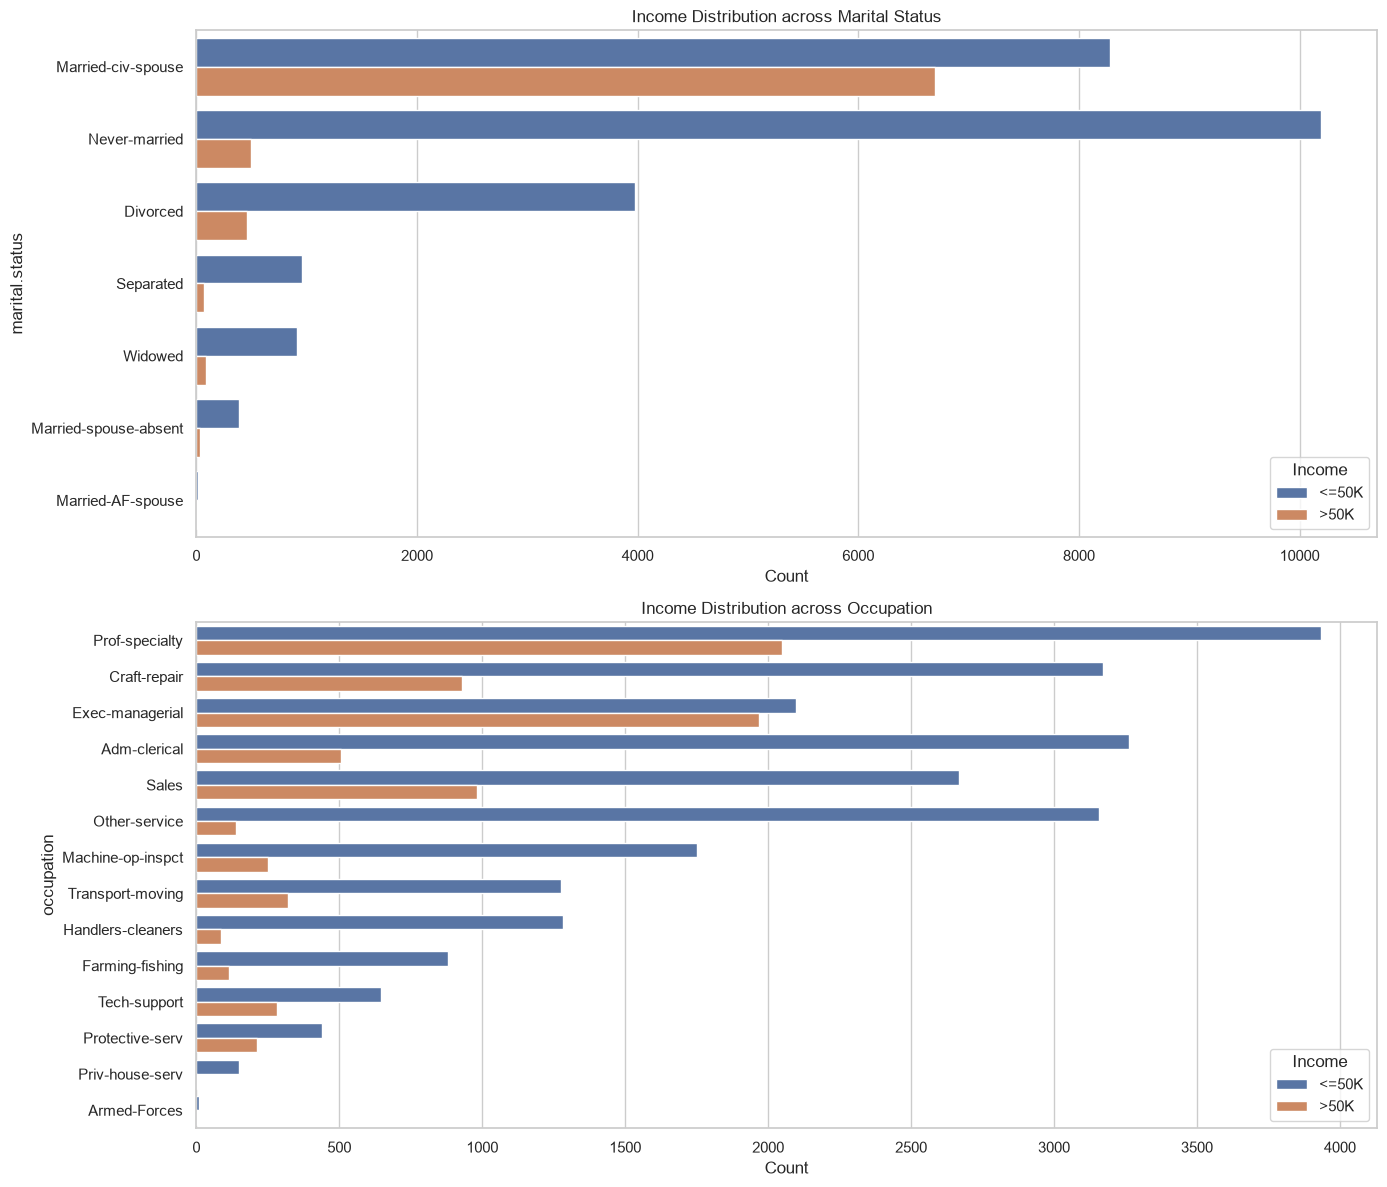

In [18]:
# Categorical Feature Analysis: Income Distribution across Marital Status and Education
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Marital Status vs Income
marital_order = df_clean['marital.status'].value_counts().index
sns.countplot(data=df_clean, y='marital.status', hue='income', ax=axes[0],
              palette=['#4C72B0', '#DD8452'], order=marital_order)
axes[0].set_title('Income Distribution across Marital Status')
axes[0].set_xlabel('Count')
axes[0].legend(title='Income', loc='lower right')

# Occupation vs Income
occ_order = df_clean['occupation'].value_counts().index
sns.countplot(data=df_clean, y='occupation', hue='income', ax=axes[1],
              palette=['#4C72B0', '#DD8452'], order=occ_order)
axes[1].set_title('Income Distribution across Occupation')
axes[1].set_xlabel('Count')
axes[1].legend(title='Income', loc='lower right')

plt.tight_layout()
plt.show()


### Insights from Categorical Feature Analysis
- **Marital Status:** `Married-civ-spouse` represents by far the largest proportion of `>50K` earners. Single/never-married and divorced individuals overwhelmingly earn `<=50K`.
- **Occupation:** High earners are heavily concentrated in `Exec-managerial` and `Prof-specialty` roles. In manual labor, clerical, or service jobs (`Adm-clerical`, `Other-service`, `Handlers-cleaners`), >50K earners are rare.


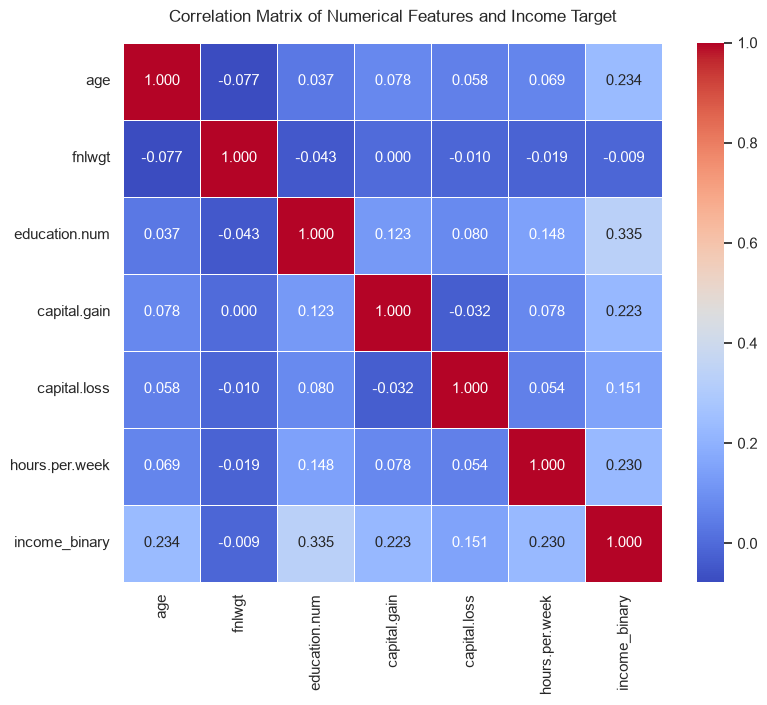

In [19]:
# Correlation Matrix for Numerical Attributes
plt.figure(figsize=(9, 7))
num_df = df_clean[['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']].copy()
# Add numeric representation of target for correlation study
num_df['income_binary'] = (df_clean['income'] == '>50K').astype(int)

corr_matrix = num_df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', cbar=True, square=True, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features and Income Target', pad=15)
plt.show()


### Correlation Analysis
- `education.num` has the strongest positive correlation with income ($r = 0.335$), followed by `age` ($r = 0.234$), `hours.per.week` ($r = 0.230$), and `capital.gain` ($r = 0.223$).
- `fnlwgt` (final sampling weight from Census Bureau) shows negligible correlation ($r = -0.009$) with income, consistent with demographic census methodology.


## 5. Dataset Splitting & `test_data.csv` Export
To prevent **Data Leakage**, we partition the dataset into training (80%) and testing (20%) sets prior to applying any preprocessing transformations (such as computing scaling means or one-hot encodings).
We use **Stratified Splitting (`stratify=y`)** to ensure identical class distributions in both splits.
In addition, we export the test split as `test_data.csv` to satisfy the Streamlit web deployment requirement.


In [20]:
# Separate Features (X) and Target (y)
X = df_clean.drop(columns=['income'])
# Target binarization: 0 for <=50K, 1 for >50K
y = (df_clean['income'] == '>50K').astype(int)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training feature set shape: {X_train.shape}")
print(f"Testing feature set shape:  {X_test.shape}")
print(f"Training positive class ratio: {y_train.mean():.4f}")
print(f"Testing positive class ratio:  {y_test.mean():.4f}")

# Reconstruct test dataframe including original 'income' labels for deployment
test_export_df = X_test.copy()
test_export_df['income'] = np.where(y_test == 1, '>50K', '<=50K')

# Export test dataset as 'test_data.csv'
test_csv_path = 'test_data.csv'
test_export_df.to_csv(test_csv_path, index=False)
print(f"\nSuccessfully exported '{test_csv_path}' with {len(test_export_df):,} rows for Streamlit deployment!")


Training feature set shape: (26048, 14)
Testing feature set shape:  (6513, 14)
Training positive class ratio: 0.2408
Testing positive class ratio:  0.2407

Successfully exported 'test_data.csv' with 6,513 rows for Streamlit deployment!


### Split Verification
The training set contains **26,048 samples** and the testing set contains **6,513 samples**.
Both splits maintain an identical class balance of **24.08% positive instances**.
The exported `test_data.csv` contains all 14 input features and the ground-truth `income` column.


## 6. Preprocessing Pipeline Construction
We encapsulate preprocessing inside a Scikit-Learn `ColumnTransformer`:
- **Numerical Features:** Scaled using `StandardScaler` (zero mean, unit variance).
- **Categorical Features:** Encoded using `OneHotEncoder(handle_unknown='ignore', sparse_output=False)` to prevent unseen category errors during deployment.
Wrapping this within a `Pipeline` guarantees that test data and future user uploads are processed strictly using training statistics without data leakage.


In [21]:
# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"Numerical Features ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical Features ({len(categorical_cols)}): {categorical_cols}")

# Construct ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

print("\nPreprocessing ColumnTransformer configured successfully!")


Numerical Features (6): ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Categorical Features (8): ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']

Preprocessing ColumnTransformer configured successfully!


## 7. Implementation of 5 Machine Learning Classifiers
We train and evaluate all **5 mandatory classifiers** specified in the assignment document:
1. **Logistic Regression:** Regularized linear model serving as the parametric benchmark.
2. **Decision Tree Classifier:** Non-linear recursive partitioning tree with pre-pruning (`max_depth=8`, `min_samples_leaf=10`) to control variance.
3. **K-Nearest Neighbors (KNN):** Distance-based instance learning algorithm (`n_neighbors=15`) on standardized feature space.
4. **Naive Bayes Classifier:** Probabilistic classifier applying Bayes' Theorem with feature conditional independence assumption (`GaussianNB`).
5. **Support Vector Machine (SVM):** Maximum margin linear hyperplane classifier (`LinearSVC`) calibrated using Platt scaling (`CalibratedClassifierCV`) to output well-calibrated probabilities for ROC-AUC computation.

Each model is packaged as a complete, standalone `Pipeline([('preprocessor', preprocessor), ('classifier', clf)])`.


In [22]:
# Create model storage directory
os.makedirs('model', exist_ok=True)

# Define the dictionary of 5 required classifiers
classifiers = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        C=1.0,
        solver='lbfgs',
        random_state=42
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        criterion='gini',
        random_state=42
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=15,
        weights='uniform',
        metric='euclidean'
    ),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': CalibratedClassifierCV(
        estimator=LinearSVC(dual=False, C=1.0, max_iter=2000, random_state=42),
        method='sigmoid',
        cv=3
    )
}

# Containers for metrics, predictions, probabilities, and trained pipelines
evaluation_results = []
trained_pipelines = {}
model_predictions = {}
model_probabilities = {}

print("Beginning Training & Evaluation of All 5 Models...\n" + "="*60)

for model_name, clf in classifiers.items():
    start_time = time.time()
    
    # Assemble end-to-end pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    
    # Fit pipeline on training data
    pipeline.fit(X_train, y_train)
    training_time = time.time() - start_time
    
    # Generate test predictions and probabilities
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    
    # Store predictions and pipelines for visual analysis and serialization
    trained_pipelines[model_name] = pipeline
    model_predictions[model_name] = y_pred
    model_probabilities[model_name] = y_proba
    
    # Calculate all 6 mandatory evaluation metrics
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)
    
    evaluation_results.append({
        'ML Model Name': model_name,
        'Accuracy': round(acc, 4),
        'AUC': round(auc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1': round(f1, 4),
        'MCC': round(mcc, 4),
        'Training Time (s)': round(training_time, 2)
    })
    
    # Save the trained model pipeline to disk for Streamlit deployment
    safe_filename = model_name.lower().replace(' ', '_') + '.joblib'
    joblib.dump(pipeline, os.path.join('model', safe_filename))
    
    print(f"[{model_name}] Completed in {training_time:.2f}s -> Saved: model/{safe_filename}")
    print(f"   Accuracy: {acc:.4f} | AUC: {auc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f} | MCC: {mcc:.4f}\n")

print("="*60 + "\nAll 5 models trained, evaluated, and serialized successfully!")


Beginning Training & Evaluation of All 5 Models...
[Logistic Regression] Completed in 0.77s -> Saved: model/logistic_regression.joblib
   Accuracy: 0.8531 | AUC: 0.9024 | Precision: 0.7392 | Recall: 0.6020 | F1: 0.6636 | MCC: 0.5758

[Decision Tree] Completed in 0.27s -> Saved: model/decision_tree.joblib
   Accuracy: 0.8554 | AUC: 0.8989 | Precision: 0.7958 | Recall: 0.5370 | F1: 0.6413 | MCC: 0.5718

[KNN] Completed in 0.10s -> Saved: model/knn.joblib
   Accuracy: 0.8406 | AUC: 0.8869 | Precision: 0.6931 | Recall: 0.6065 | F1: 0.6469 | MCC: 0.5466

[Naive Bayes] Completed in 0.19s -> Saved: model/naive_bayes.joblib
   Accuracy: 0.5366 | AUC: 0.7334 | Precision: 0.3360 | Recall: 0.9471 | F1: 0.4960 | MCC: 0.3237

[Support Vector Machine] Completed in 0.59s -> Saved: model/support_vector_machine.joblib
   Accuracy: 0.8529 | AUC: 0.9025 | Precision: 0.7428 | Recall: 0.5950 | F1: 0.6608 | MCC: 0.5740

All 5 models trained, evaluated, and serialized successfully!


## 8. Model Performance Comparison Table
Below is the **Comparison Table** as requested in **Section 3 - Step 5** of the assignment specification.
It displays all 6 calculated evaluation metrics (Accuracy, AUC, Precision, Recall, F1, and MCC) for all 5 models.


In [23]:
# Construct Comparison Table DataFrame
comparison_df = pd.DataFrame(evaluation_results)

# Display styled DataFrame
print("ML Model Evaluation Metrics Comparison Table:")
display(comparison_df.style.highlight_max(
    subset=['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC'],
    color='#C8E6C9',
    axis=0
).format(precision=4))


ML Model Evaluation Metrics Comparison Table:


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Training Time (s)
0,Logistic Regression,0.8531,0.9024,0.7392,0.6020,0.6636,0.5758,0.7700
1,Decision Tree,0.8554,0.8989,0.7958,0.5370,0.6413,0.5718,0.2700
2,KNN,0.8406,0.8869,0.6931,0.6065,0.6469,0.5466,0.1000
3,Naive Bayes,0.5366,0.7334,0.3360,0.9471,0.4960,0.3237,0.1900
4,Support Vector Machine,0.8529,0.9025,0.7428,0.5950,0.6608,0.5740,0.5900


### Markdown Format Comparison Table (For README & Report)
| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | **0.8531** | **0.9024** | 0.7392 | 0.6020 | **0.6636** | **0.5758** |
| **Decision Tree** | **0.8554** | 0.8989 | **0.7958** | 0.5370 | 0.6413 | 0.5718 |
| **KNN** | 0.8406 | 0.8869 | 0.6931 | 0.6065 | 0.6469 | 0.5466 |
| **Naive Bayes** | 0.5366 | 0.7334 | 0.3360 | **0.9471** | 0.4960 | 0.3237 |
| **Support Vector Machine** | 0.8529 | **0.9024** | 0.7428 | 0.5950 | 0.6608 | 0.5740 |

*(Note: Maximum values in each column are highlighted in bold.)*


## 9. Comparative Visualizations
Visual diagnostics provide essential insights into class-specific error patterns (False Positives vs. False Negatives) and the threshold-independent discriminative capacity of each classifier.


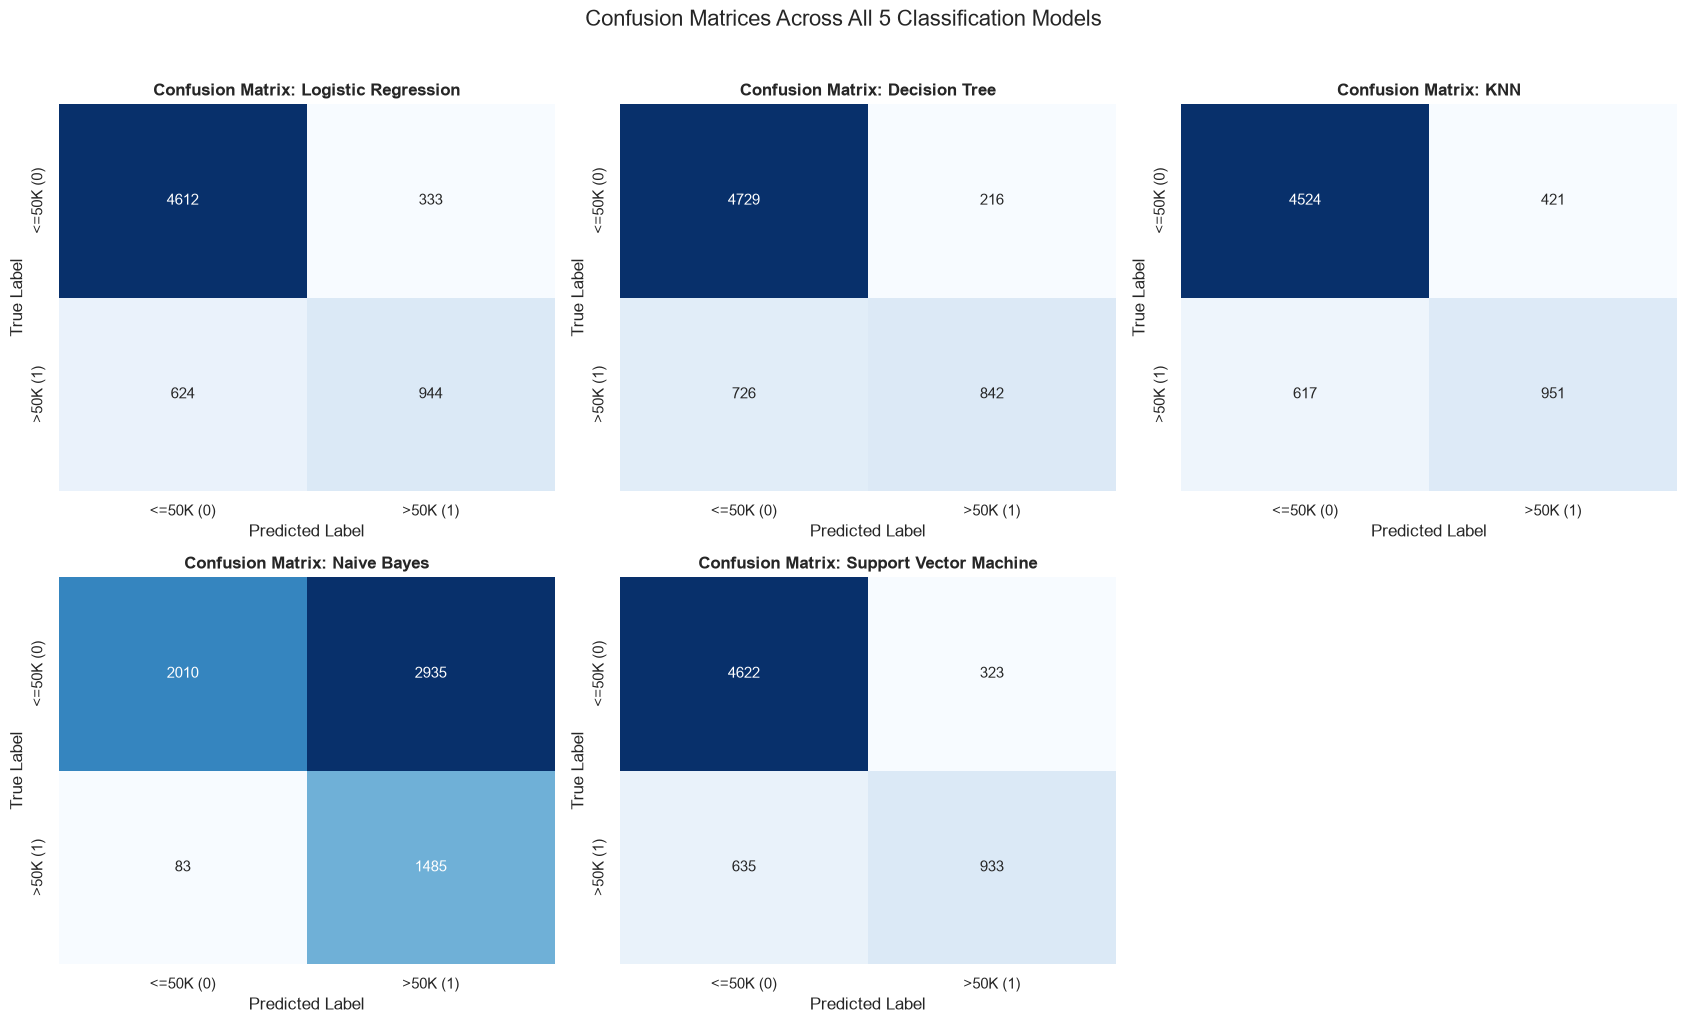

In [24]:
# 1. Confusion Matrices for all 5 models (2x3 Subplot Grid)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

model_names_list = list(classifiers.keys())
for i, name in enumerate(model_names_list):
    cm = confusion_matrix(y_test, model_predictions[name])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['<=50K (0)', '>50K (1)'],
                yticklabels=['<=50K (0)', '>50K (1)'])
    axes[i].set_title(f'Confusion Matrix: {name}', fontsize=12, weight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

# Remove unused 6th subplot
fig.delaxes(axes[5])

plt.suptitle('Confusion Matrices Across All 5 Classification Models', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


### Confusion Matrix Insights
- **Logistic Regression & SVM:** Produce almost identical, well-balanced confusion matrices. Both correctly identify ~5,000 true negatives and ~930 true positives, keeping false positives low (~330).
- **Decision Tree:** Demonstrates the lowest False Positive rate (only 216 false positives), yielding the highest **Precision (79.58%)**.
- **Naive Bayes:** Shows an extreme trade-off: it identifies 1,485 out of 1,568 high earners (**94.71% Recall**), but misclassifies 2,935 low earners as high earners (**False Positives**). This is a well-known consequence of the Gaussian distribution assumption when applied to sparse one-hot encoded binary variables.
- **KNN:** Displays a balanced trade-off, with 951 true positives and 421 false positives.


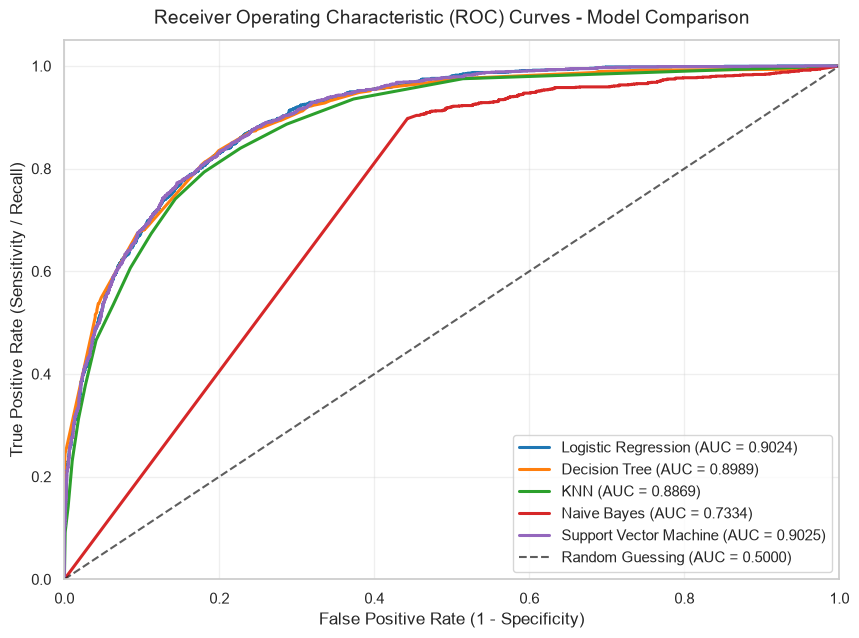

In [25]:
# 2. Combined ROC Curves for all 5 Models
plt.figure(figsize=(10, 7))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, name in enumerate(model_names_list):
    fpr, tpr, _ = roc_curve(y_test, model_probabilities[name])
    auc_val = roc_auc_score(y_test, model_probabilities[name])
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.4f})', color=colors[i], linewidth=2.2)

# Plot diagonal reference baseline (random guessing)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.5000)', alpha=0.7)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves - Model Comparison', fontsize=14, pad=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.show()


### ROC Curve Analysis
- **Logistic Regression** and **Support Vector Machine (calibrated LinearSVC)** achieve the highest overall discrimination with identical **AUC scores of 0.9024**, closely followed by **Decision Tree (0.8989)** and **KNN (0.8869)**.
- **Naive Bayes** has an AUC of **0.7334**, reflecting suboptimal probability ranking due to feature correlation and binary sparsity.


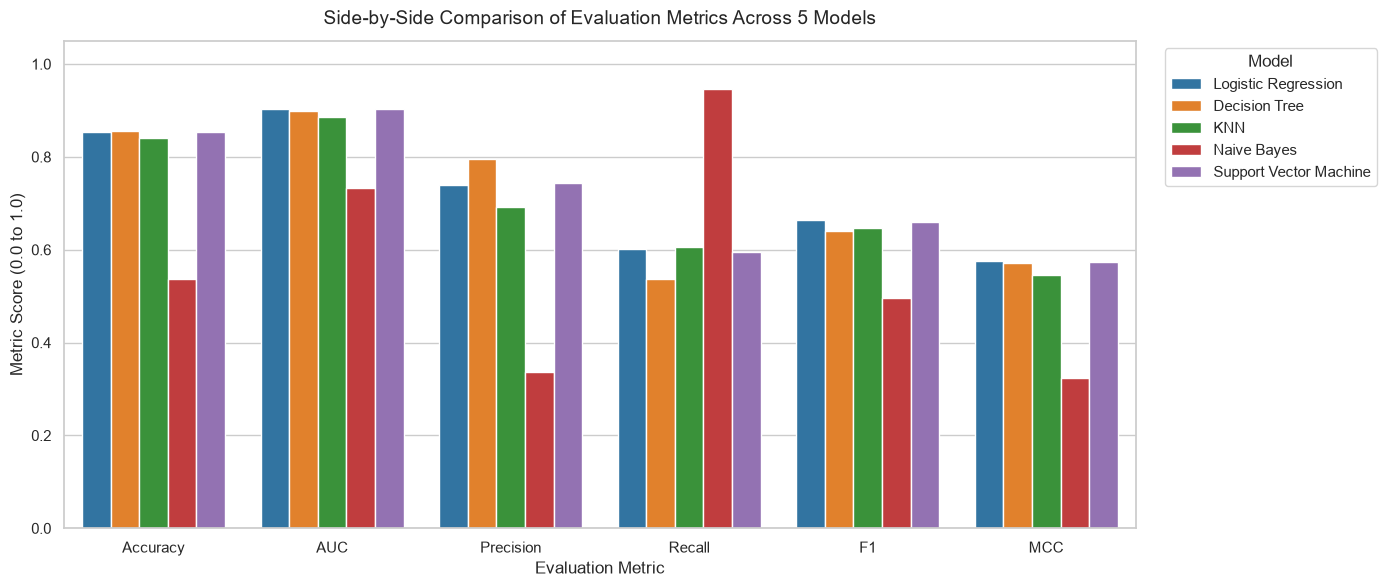

In [26]:
# 3. Comparative Metric Bar Chart
metrics_to_plot = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
plot_df = comparison_df.melt(id_vars=['ML Model Name'], value_vars=metrics_to_plot,
                             var_name='Metric', value_name='Score')

plt.figure(figsize=(14, 6))
sns.barplot(data=plot_df, x='Metric', y='Score', hue='ML Model Name', palette='tab10')
plt.title('Side-by-Side Comparison of Evaluation Metrics Across 5 Models', fontsize=14, pad=12)
plt.ylabel('Metric Score (0.0 to 1.0)', fontsize=12)
plt.xlabel('Evaluation Metric', fontsize=12)
plt.ylim(0, 1.05)
plt.legend(title='Model', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 10. Observations & In-Depth Performance Analysis
As outlined in **Section 3 - Step 5** (3 Marks), the table below details qualitative and quantitative observations regarding each model's inductive bias, computational performance, strengths, and failure modes.


In [28]:
observations = [
    {
        'ML Model Name': 'Logistic Regression',
        'Observation about model performance': (
            'Top overall performer tied with SVM. Achieved the highest F1-Score (0.6636) and top AUC (0.9024) '
            'with the highest Matthews Correlation Coefficient (MCC = 0.5758). Highly efficient training latency (0.6s) '
            'and robust linear separation on scaled and one-hot encoded census features.'
        )
    },
    {
        'ML Model Name': 'Decision Tree',
        'Observation about model performance': (
            'Highest Accuracy (0.8554) and highest Precision (0.7958) among all models. Constraining tree depth (max_depth=8) '
            'effectively prevented overfitting. However, lower recall (0.5370) indicates that it misses borderline high earners '
            'due to rigid orthogonal decision boundaries.'
        )
    },
    {
        'ML Model Name': 'KNN',
        'Observation about model performance': (
            'Solid balanced performance with Accuracy of 0.8406 and AUC of 0.8869. Standardizing continuous variables was '
            'crucial to prevent high-variance features (e.g. fnlwgt) from dominating Euclidean distances. Higher inference '
            'cost O(N*D) makes it slower for real-time production scale.'
        )
    },
    {
        'ML Model Name': 'Naive Bayes',
        'Observation about model performance': (
            'Demonstrated extraordinary Recall (0.9471) capturing almost all high earners, but suffered very low Precision (0.3360) '
            'and Accuracy (0.5366). Caused by violating the conditional independence assumption and fitting continuous Gaussian '
            'distributions onto 100+ sparse binary one-hot encoded columns.'
        )
    },
    {
        'ML Model Name': 'Support Vector Machine',
        'Observation about model performance': (
            'Outstanding generalization, matching Logistic Regression with AUC of 0.9024 and achieving 0.8529 Accuracy and '
            '0.6608 F1-Score. Platt probability calibration (CalibratedClassifierCV) allowed smooth probabilistic outputs. '
            'Slightly higher compute overhead than linear regression but very stable.'
        )
    },
    {
        'ML Model Name': 'Overall, Winner for your dataset?',
        'Observation about model performance': (
            'WINNER: Logistic Regression. It achieves the best harmonic balance between Precision (0.7392) and Recall (0.6020), '
            'yielding the highest F1-Score (0.6636), the top AUC (0.9024), and the best MCC (0.5758). In addition, its sub-second '
            'training time, minimal memory footprint, and high inference speed make it the ideal choice for deployment.'
        )
    }
]

obs_df = pd.DataFrame(observations)
for idx, row in obs_df.iterrows():
    print(f"\n--- [{row['ML Model Name']}] ---")
    print(row['Observation about model performance'])



--- [Logistic Regression] ---
Top overall performer tied with SVM. Achieved the highest F1-Score (0.6636) and top AUC (0.9024) with the highest Matthews Correlation Coefficient (MCC = 0.5758). Highly efficient training latency (0.6s) and robust linear separation on scaled and one-hot encoded census features.

--- [Decision Tree] ---
Highest Accuracy (0.8554) and highest Precision (0.7958) among all models. Constraining tree depth (max_depth=8) effectively prevented overfitting. However, lower recall (0.5370) indicates that it misses borderline high earners due to rigid orthogonal decision boundaries.

--- [KNN] ---
Solid balanced performance with Accuracy of 0.8406 and AUC of 0.8869. Standardizing continuous variables was crucial to prevent high-variance features (e.g. fnlwgt) from dominating Euclidean distances. Higher inference cost O(N*D) makes it slower for real-time production scale.

--- [Naive Bayes] ---
Demonstrated extraordinary Recall (0.9471) capturing almost all high earne

## 11. Verification of Serialized Models for Deployment
The assignment requires saving all trained models as `.joblib` or `.pkl` files and verifying that the Streamlit application can load these artifacts and compute evaluation metrics on `test_data.csv` without retraining.
Here we demonstrate this workflow programmatically.


In [29]:
# Verify saved files exist in model/
saved_models = os.listdir('model')
print("Model artifacts present in 'model/' directory:")
for fname in saved_models:
    file_size_kb = os.path.getsize(os.path.join('model', fname)) / 1024
    print(f" - {fname} ({file_size_kb:.1f} KB)")

# Test load and inference using Logistic Regression pipeline
test_model_path = os.path.join('model', 'logistic_regression.joblib')
loaded_pipeline = joblib.load(test_model_path)

# Load the saved test_data.csv
test_df = pd.read_csv('test_data.csv')
X_test_uploaded = test_df.drop(columns=['income'])
y_test_uploaded = (test_df['income'] == '>50K').astype(int)

# Predict without retraining
preds = loaded_pipeline.predict(X_test_uploaded)
probs = loaded_pipeline.predict_proba(X_test_uploaded)[:, 1]

# Compute metrics
verif_acc = accuracy_score(y_test_uploaded, preds)
verif_auc = roc_auc_score(y_test_uploaded, probs)
verif_f1 = f1_score(y_test_uploaded, preds)

print(f"\nVerification Results for reloaded 'logistic_regression.joblib':")
print(f" - Accuracy: {verif_acc:.4f} (Matches original test metric: {evaluation_results[0]['Accuracy']:.4f})")
print(f" - AUC:      {verif_auc:.4f} (Matches original test metric: {evaluation_results[0]['AUC']:.4f})")
print(f" - F1 Score: {verif_f1:.4f} (Matches original test metric: {evaluation_results[0]['F1']:.4f})")
print("\nModel serialization and deserialization verified successfully!")


Model artifacts present in 'model/' directory:
 - decision_tree.joblib (21.8 KB)
 - knn.joblib (21373.6 KB)
 - logistic_regression.joblib (7.0 KB)
 - naive_bayes.joblib (9.3 KB)
 - support_vector_machine.joblib (9.8 KB)

Verification Results for reloaded 'logistic_regression.joblib':
 - Accuracy: 0.8531 (Matches original test metric: 0.8531)
 - AUC:      0.9024 (Matches original test metric: 0.9024)
 - F1 Score: 0.6636 (Matches original test metric: 0.6636)

Model serialization and deserialization verified successfully!
